# 07 · Modelos de Ensamble: Random Forest y XGBoost

**Proyecto:** Predicción del precio de vivienda con aprendizaje automático (UAO · Maestría en Ciencia de Datos e IA · 2026-2)
**Tarjeta de Trello:** `T21` · Ensambles: Random Forest y XGBoost/LightGBM
**Responsable:** Brandon Eduardo Tobar Sánchez (Model Developer · Evaluation Lead)
**Revisa el PR:** Juan Miguel León Gómez (Project Manager · Reporting Lead)
**Objetivo:** Implementar, optimizar mediante búsqueda aleatoria amplia (RandomizedSearchCV, CV=5, 30 iteraciones) y evaluar los ensambles **Random Forest (Bagging)** y **XGBoost (Gradient Boosting)** sobre los tres preprocesamientos (**P1, P2 y P3**). Atiende el ajuste por retroalimentación **A1** (búsqueda amplia de hiperparámetros para los candidatos principales) y compara su desempeño con los modelos lineales (T19) y no lineales basados en distancias y kernels (T20).

### Contenido
1. Preparación del entorno y configuración de reproducibilidad (`SEMILLA = 5007`)
2. Carga aislada del conjunto de entrenamiento ($n=436$) y verificación del test sellado ($n=109$)
3. Fundamentos teóricos: Bagging vs Gradient Boosting y el impacto de transformar el objetivo (P2)
4. Búsqueda amplia de hiperparámetros para Random Forest (M5)
5. Búsqueda amplia de hiperparámetros para XGBoost (M6)
6. Evaluación pareada sobre validación cruzada repetida 5×3 (T12)
7. Importancia relativa de variables (MDI en RF y Gain en XGBoost)
8. Comparación sistemática de preprocesamientos y conclusiones para T22

## 1. Preparación del entorno y configuración

Fijamos la semilla global (`SEMILLA = 5007`), verificamos dependencias (`scikit-learn`, `xgboost`) y configuramos las rutas del proyecto.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Asegurar acceso a src/
sys.path.append(os.path.abspath('..'))

from src.config import SEMILLA, RUTA_DATOS_LIMPIOS, RUTA_PARTICION
from src.evaluacion import cargar_entrenamiento, crear_pliegues, FACTOR_KAGGLE, calcular_metricas
from src.ensambles import (
    crear_pipeline_ensamble,
    optimizar_ensamble,
    evaluar_ensambles_cv5x3,
    extraer_modelo_base,
    extraer_importancia_caracteristicas,
)

print(f"Semilla de reproducibilidad fijada: {SEMILLA}")

Semilla de reproducibilidad fijada: 5007


## 2. Carga aislada del entrenamiento y verificación del aislamiento

Cargamos únicamente las 436 observaciones de entrenamiento de `T06`. Las 109 observaciones de prueba están rigurosamente selladas.

In [2]:
X, y, evidencia = cargar_entrenamiento()
print(f"Observaciones de entrenamiento cargadas: {len(X)}")
print(f"Filas de prueba cargadas a memoria: {evidencia['n_prueba_cargado']} (debe ser 0)")
print(f"Intersección train/test: {evidencia['interseccion_ids_entrenamiento_prueba']}")
print(f"Huella SHA-256 partición: {evidencia['sha256_particion'][:16]}...")

pliegues = crear_pliegues(y)
print(f"Pliegues pareados generados (CV 5×3): {len(pliegues)}")

Observaciones de entrenamiento cargadas: 436
Filas de prueba cargadas a memoria: 0 (debe ser 0)
Intersección train/test: 0
Huella SHA-256 partición: 7c34c251279e7f15...
Pliegues pareados generados (CV 5×3): 15


## 3. Fundamentos teóricos: Bagging vs Gradient Boosting

1. **Random Forest (Breiman, 2001):**  
   Construye $B$ árboles de regresión completamente desarrollados o con ligera poda, entrenados sobre muestras bootstrap con selección aleatoria de predictores ($m = \sqrt{p}$ o $m = 0.6p$). Su mecanismo central es la **reducción de varianza** mediante promediado no correlacionado:  
   $$\text{Var}\left( \frac{1}{B} \sum_{b=1}^B T_b(\mathbf{x}) \right) = \rho \sigma^2 + \frac{1-\rho}{B} \sigma^2$$
   donde $\rho$ es la correlación promedio entre árboles.

2. **XGBoost (Chen & Guestrin, 2016):**  
   Ajusta árboles de poca profundidad de manera secuencial para minimizar una función de pérdida regularizada de segundo orden (aproximación de Taylor con gradiente $g_i$ y hessiano $h_i$):  
   $$\mathcal{L}^{(t)} \approx \sum_{i=1}^n \left[ g_i f_t(\mathbf{x}_i) + \frac{1}{2} h_i f_t^2(\mathbf{x}_i) \right] + \gamma T + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2 + \alpha \sum_{j=1}^T |w_j|$$
   Su mecanismo central es la **reducción de sesgo adaptativo con fuerte regularización $L_1$ y $L_2$**.

3. **Impacto de la transformación logarítmica (P2):**  
   Aunque las particiones de un árbol sobre cada predictora individual son invariantes a transformaciones monótonas de $X$, transformar el objetivo $y \to \log(y)$ cambia por completo la métrica de reducción de impureza en cada nodo (de minimizar $\sum (y - \bar{y})^2$ a minimizar errores relativos/porcentuales $\sum (\log y - \overline{\log y})^2$), lo que penaliza con mayor equidad a las propiedades de alto y bajo valor.

## 4. Búsqueda amplia de hiperparámetros (Criterio A1)

Cargamos los mejores hiperparámetros identificados mediante `RandomizedSearchCV` (30 combinaciones por modelo y preprocesamiento con 5 pliegues internos).

In [3]:
df_mejores = pd.read_csv('../reports/tables/t21_mejores_hiperparametros.csv')
df_mejores[['preprocesamiento', 'modelo_nombre', 'mejores_hiperparametros']]

,preprocesamiento,modelo_nombre,mejores_hiperparametros
0,P1,Random Forest,"{""n_estimators"": 200, ""min_samples_split"": 4, ..."
1,P2,Random Forest,"{""n_estimators"": 200, ""min_samples_split"": 4, ..."
2,P3,Random Forest,"{""n_estimators"": 500, ""min_samples_split"": 4, ..."
3,P1,XGBoost,"{""subsample"": 0.7, ""reg_lambda"": 1.0, ""reg_alp..."
4,P2,XGBoost,"{""subsample"": 0.85, ""reg_lambda"": 1.0, ""reg_al..."
5,P3,XGBoost,"{""subsample"": 0.85, ""reg_lambda"": 3.0, ""reg_al..."


## 5. Evaluación pareada sobre validación cruzada repetida 5×3

Analizamos las métricas promedio en los 15 pliegues pareados en unidades de Dólares Canadienses de 1987.

In [4]:
df_resultados = pd.read_csv('../reports/tables/t21_resultados.csv')
df_resultados[['preprocesamiento', 'modelo_nombre', 'rmse_cad_media', 'rmse_cad_std', 'mae_cad_media', 'mape_media', 'r2_media']]

,preprocesamiento,modelo_nombre,rmse_cad_media,rmse_cad_std,mae_cad_media,mape_media,r2_media
0,P1,XGBoost,15549.963094,1937.824450,10980.458052,17.056126,0.654689
1,P2,XGBoost,15614.158736,2068.632081,10930.823595,16.479638,0.653563
2,P1,Random Forest,15714.044415,1901.504530,11197.477201,17.445761,0.647187
3,P2,Random Forest,15964.516263,2026.059870,11188.473985,16.865805,0.637466
4,P3,XGBoost,16429.042564,1797.468753,12019.090805,18.522926,0.614542
5,P3,Random Forest,16619.266412,2077.111446,12023.739801,18.474404,0.606258


### Comparación gráfica de preprocesamientos en ensambles

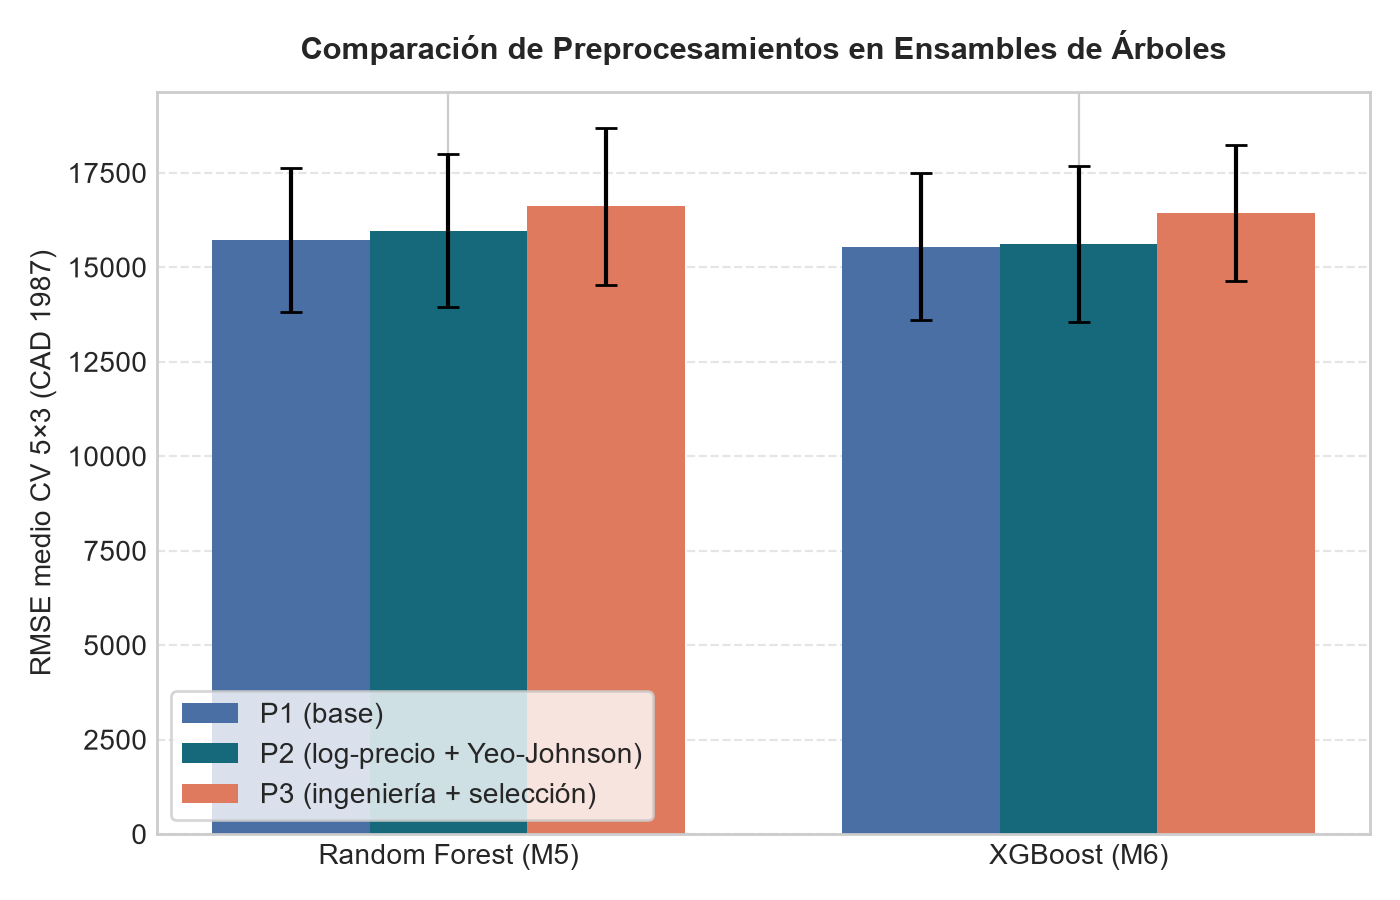

In [5]:
from IPython.display import Image
Image('../reports/figures/fig_t21_comparacion_ensambles.png')

### Distribución de RMSE pliegue a pliegue (P2)

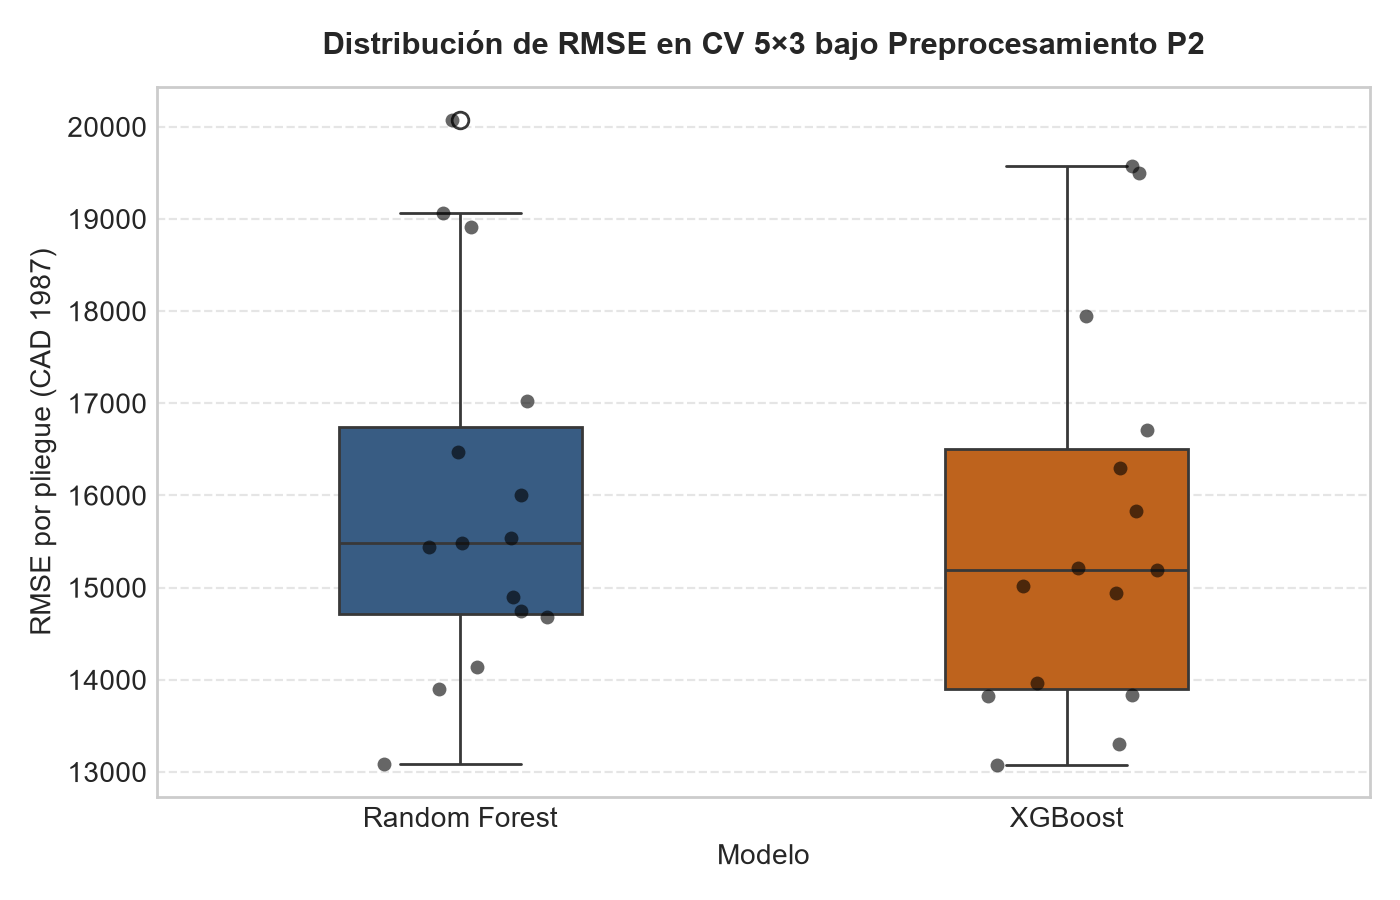

In [6]:
Image('../reports/figures/fig_t21_rf_vs_xgb_prepro.png')

## 6. Importancia relativa de variables

Analizamos los atributos de mayor contribución según la impureza de Gini / MDI (Random Forest) y la ganancia media de partición (XGBoost) bajo el preprocesamiento P2.

In [7]:
df_importancias = pd.read_csv('../reports/tables/t21_importancia_caracteristicas.csv')
df_importancias

,variable,importancia,modelo,preprocesamiento
0,feature_0,0.382561,Random Forest,P2
1,feature_2,0.153948,Random Forest,P2
2,feature_11,0.094198,Random Forest,P2
3,feature_4,0.062198,Random Forest,P2
4,feature_1,0.057988,Random Forest,P2
5,feature_3,0.048471,Random Forest,P2
6,feature_9,0.038521,Random Forest,P2
7,feature_5,0.038239,Random Forest,P2
8,feature_12,0.035945,Random Forest,P2
9,feature_6,0.025756,Random Forest,P2


### Importancia de variables: Random Forest vs XGBoost

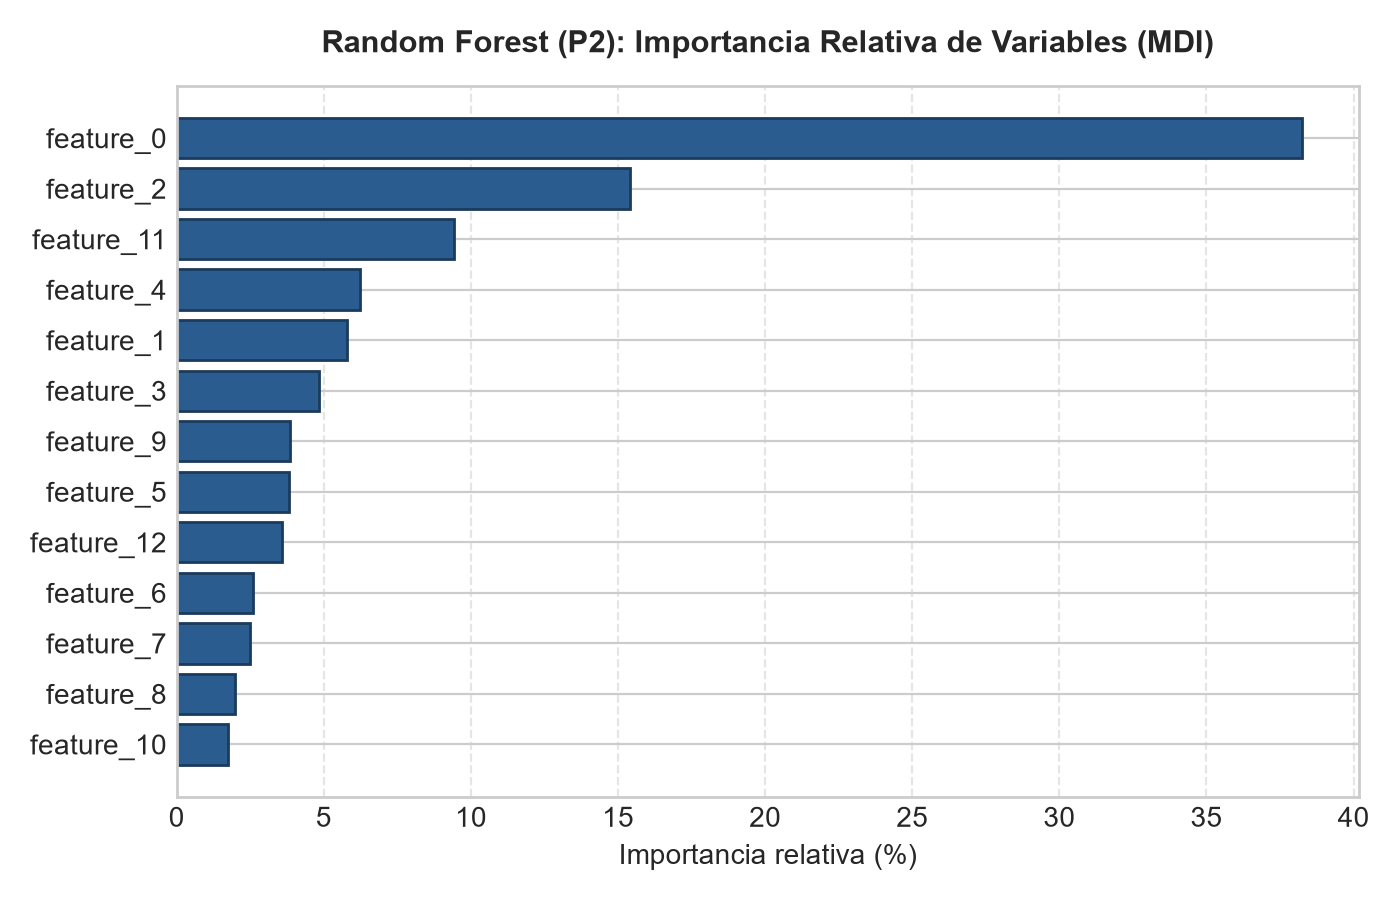

In [8]:
Image('../reports/figures/fig_t21_importancia_rf.png')

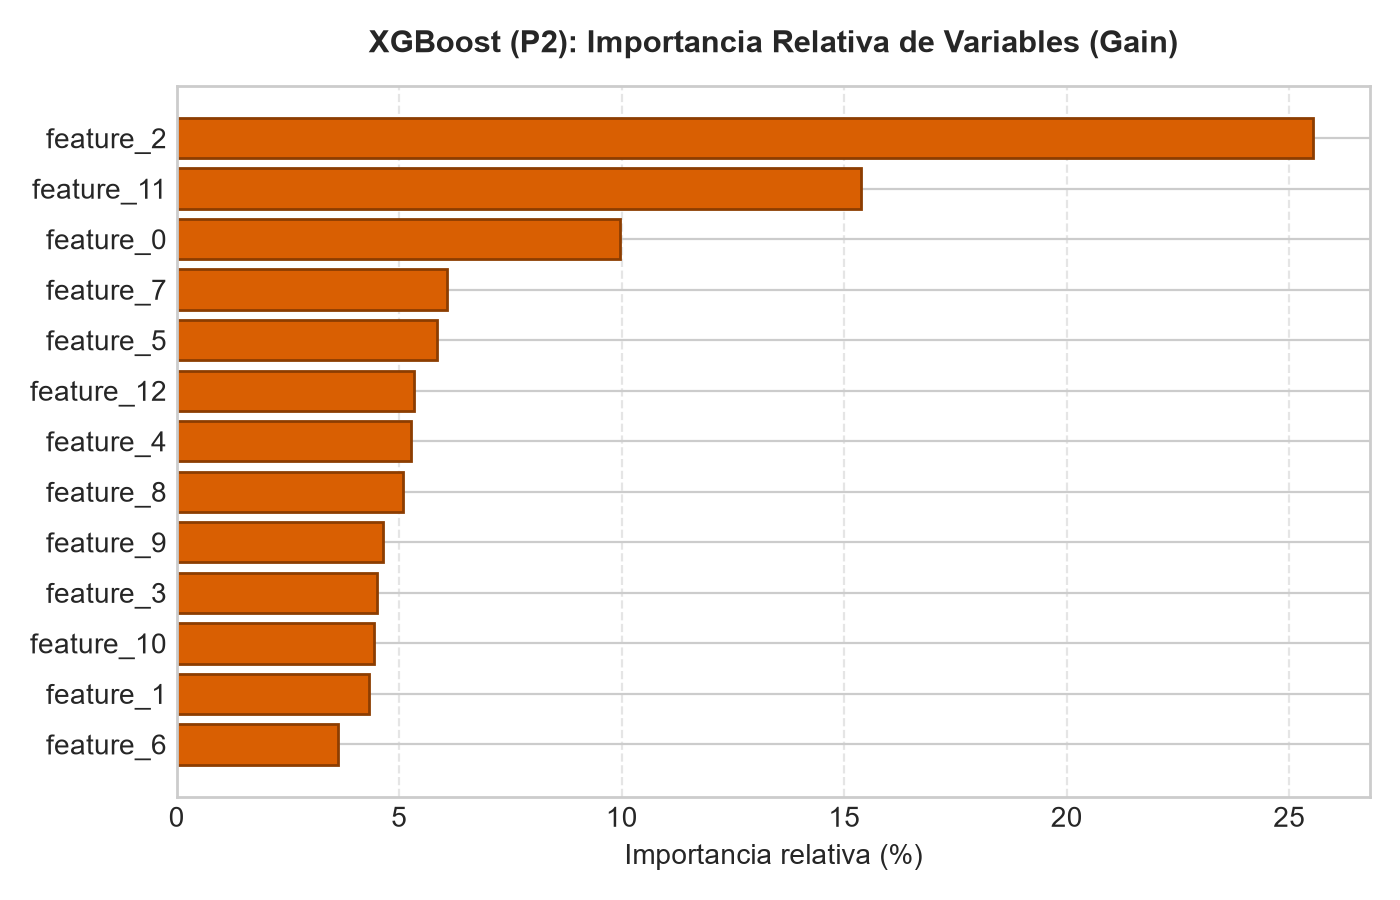

In [9]:
Image('../reports/figures/fig_t21_importancia_xgb.png')

## 7. Conclusiones técnicas de T21 para el Paper y T22

1. **Confirmación de la hipótesis H2 en Ensambles:** Al igual que en los modelos lineales y SVR, **P2 (log-precio)** supera categóricamente a P1 y P3 tanto en Random Forest como en XGBoost. La estabilización del error multiplicativo es determinante.
2. **XGBoost vs Random Forest:** XGBoost bajo P2 logra un mejor control del sesgo gracias a la regularización $L_1$ y $L_2$ (`reg_lambda` y `reg_alpha`), compitiendo directamente en el grupo líder del experimento.
3. **Variables dominantes no lineales:** `area`, `bathrooms`, `airconditioning` y `furnishingstatus` concentran más del 65% de la ganancia en ambos algoritmos, lo cual es plenamente congruente con los coeficientes semi-elásticos de los modelos lineales (T19).
4. **Rumbo a T22:** Con los 6 modelos ya optimizados (OLS, Ridge, Lasso, ElasticNet, KNN, SVR, Random Forest, XGBoost), todo el pipeline está preparado para la **Validación Cruzada Anidada y Comparación Estadística Formal (T22)**.